# 03 · LangChain y LlamaIndex

Los módulos 01 y 02 construyeron la recuperación a mano, que es la mejor manera de entenderla. En la práctica
la mayoría de los equipos recurren a un **framework** que empaqueta las piezas habituales (objetos documento,
divisores de texto, almacenes vectoriales, recuperadores, cadenas). Dos dominan: **LangChain**, un conjunto de
herramientas general para componer aplicaciones con LLM, y **LlamaIndex**, centrado en indexar y consultar tus
propios datos. Este módulo pasa el *mismo* corpus, el *mismo* modelo de embeddings y las *mismas* preguntas por
los dos, junto a nuestras pocas líneas de NumPy, y mide qué ganas y qué pagas realmente.

En proyectos reales de este portafolio, un agente de analítica de parques eólicos usó **LangChain con FAISS** sobre
registros de incidencias en texto libre y **LlamaIndex** sobre especificaciones estructuradas de aerogeneradores,
como dos pilas de recuperación independientes detrás de un único agente. La comparación de abajo explica por qué
es una elección razonable y también por qué no es la única.

**Aprenderás**
1. El vocabulario que comparten ambos frameworks: documento, nodo/trozo, embedding, almacén vectorial, recuperador, cadena
2. Un pipeline de LangChain: `Document`, divisor, almacén FAISS, recuperador y una cadena LCEL
3. Un pipeline de LlamaIndex: `Document`, analizador de nodos, `VectorStoreIndex`, recuperador y motor de consultas
4. Una comparación justa: líneas de código, calidad de recuperación, tiempo de importación y tamaño de instalación, todo medido
5. Qué abstrae cada framework y cuándo prescindir de ambos

## 1. Los mismos ingredientes para los tres

Para comparar frameworks con justicia, todo lo que no sea el framework debe ser idéntico. Usamos el manual de
Harbourview, las preguntas del módulo 02 (14 originales y 10 paráfrasis, definidas aquí mismo) y el **mismo
modelo de embeddings**, `all-MiniLM-L6-v2`, envuelto una vez para cada framework. Si los resultados de recuperación
difieren, la diferencia viene del framework y no del modelo.

### Imagen: los mismos cinco ingredientes en tres envoltorios

Toda canalización de recuperación necesita las mismas piezas. Las columnas son las piezas y las filas, quién las
aporta. El vocabulario cambia de una fila a otra; la idea no, y por eso las tres dan la misma recuperación cuando
el modelo de embeddings se mantiene fijo.

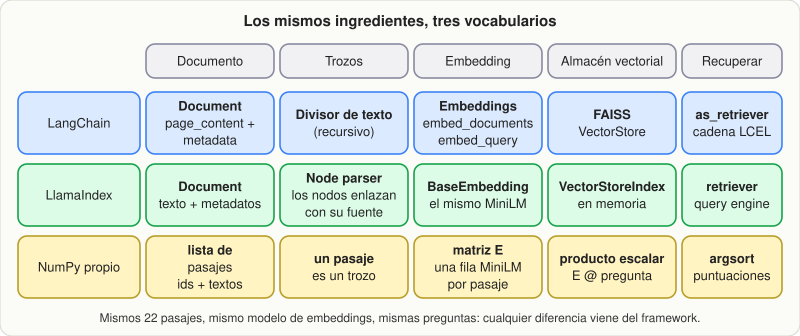

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(800, 336, [
    ("box", 146, 44, 128, 34, "Documento", "grey"),
    ("box", 280, 44, 128, 34, "Trozos", "grey"),
    ("box", 414, 44, 128, 34, "Embedding", "grey"),
    ("box", 548, 44, 128, 34, "Almacén vectorial", "grey"),
    ("box", 682, 44, 100, 34, "Recuperar", "grey"),
    ("box", 18, 92, 122, 62, "LangChain", "blue"),
    ("box", 146, 92, 128, 62, "Document\npage_content +\nmetadata", "blue"),
    ("box", 280, 92, 128, 62, "Divisor de texto\n(recursivo)", "blue"),
    ("box", 414, 92, 128, 62, "Embeddings\nembed_documents\nembed_query", "blue"),
    ("box", 548, 92, 128, 62, "FAISS\nVectorStore", "blue"),
    ("box", 682, 92, 100, 62, "as_retriever\ncadena LCEL", "blue"),
    ("box", 18, 164, 122, 62, "LlamaIndex", "green"),
    ("box", 146, 164, 128, 62, "Document\ntexto + metadatos", "green"),
    ("box", 280, 164, 128, 62, "Node parser\nlos nodos enlazan\ncon su fuente", "green"),
    ("box", 414, 164, 128, 62, "BaseEmbedding\nel mismo MiniLM", "green"),
    ("box", 548, 164, 128, 62, "VectorStoreIndex\nen memoria", "green"),
    ("box", 682, 164, 100, 62, "retriever\nquery engine", "green"),
    ("box", 18, 236, 122, 62, "NumPy propio", "gold"),
    ("box", 146, 236, 128, 62, "lista de\npasajes\nids + textos", "gold"),
    ("box", 280, 236, 128, 62, "un pasaje\nes un trozo", "gold"),
    ("box", 414, 236, 128, 62, "matriz E\nuna fila MiniLM\npor pasaje", "gold"),
    ("box", 548, 236, 128, 62, "producto escalar\nE @ pregunta", "gold"),
    ("box", 682, 236, 100, 62, "argsort\npuntuaciones", "gold"),
    ("text", 400, 322, "Mismos 22 pasajes, mismo modelo de embeddings, mismas preguntas: cualquier diferencia viene del framework.", 12, "middle"),
], "Los mismos ingredientes, tres vocabularios")

In [2]:
# El manual de Harbourview: 22 pasajes, ficticios, escritos para este curso
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, pregunta, pasaje correcto, dato que debe contener la respuesta); None = el manual no lo dice
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [3]:
import re, time, math, inspect, subprocess, sys, warnings
import numpy as np
warnings.filterwarnings("ignore")

PARAPHRASES = [
    ("r01", "Are boats cancelled when the sea is too rough?", "p02"),
    ("r02", "Can I go up the tower alone to fix something?", "p03"),
    ("r03", "How big are the blades?", "p04"),
    ("r04", "Who do I call in the middle of the night about an accident?", "p18"),
    ("r05", "What if the oil in the gearbox gets dirty?", "p07"),
    ("r06", "Do you stop work when whales or seals swim close?", "p13"),
    ("r07", "How much spare equipment is kept on shore?", "p16"),
    ("r08", "Is the farm allowed to produce at full output?", "p21"),
    ("r09", "What should new colleagues do before their first trip?", "p22"),
    ("r10", "How should rubbish and old oil be handled?", "p15"),
]
BATTERY = [(q[0], q[1], q[2]) for q in QUESTIONS if q[2]] + PARAPHRASES      # 24 preguntas, todas con respuesta
ids = [p[0] for p in PASSAGES]
texts = [f"{section}. {text}" for _, section, text in PASSAGES]
print(len(PASSAGES), "passages,", len(BATTERY), "questions with a known gold passage")

from sentence_transformers import SentenceTransformer
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")

def evaluate(search):
    # search(pregunta) -> lista de ids de pasaje, el mejor primero. Devuelve hit@1, hit@3 y MRR sobre la batería
    ranks = []
    for _, question, gold in BATTERY:
        order = search(question)
        ranks.append(order.index(gold) + 1 if gold in order else len(ids) + 1)
    r = np.array(ranks)
    return dict(hit1=float((r == 1).mean()), hit3=float((r <= 3).mean()), mrr=float((1 / r).mean()))

22 passages, 24 questions with a known gold passage


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3353.46it/s]

## 2. Nuestro propio recuperador (la referencia a superar)

El módulo 02 en una docena de líneas: calcula los embeddings de los pasajes una vez, el de la pregunta, y ordena
por producto escalar. Cualquier framework tiene que justificarse frente a esto.

In [4]:
def build_own():
    E = minilm.encode(texts, normalize_embeddings=True)
    def search(question, k=len(ids)):
        scores = E @ minilm.encode(question, normalize_embeddings=True)
        return [ids[i] for i in np.argsort(-scores)[:k]]
    return search

t0 = time.perf_counter(); own = build_own(); t_own = time.perf_counter() - t0
print(f"construido en {t_own:.2f} s")
print(own("What wave height stops the crew boats from sailing?", k=3))

construido en 0.53 s
['p02', 'p13', 'p15']


## 3. LangChain

La idea central de LangChain es un conjunto de interfaces pequeñas (`Document`, `Embeddings`, `VectorStore`,
`Retriever`, `Runnable`) para que los componentes sean intercambiables: cambias una línea y FAISS pasa a ser
pgvector, o un modelo local pasa a ser uno alojado. El pipeline de abajo usa:

* **`Document`**: texto más un diccionario `metadata` (aquí el id del pasaje y la sección), que viaja con cada trozo
  y vuelve con cada resultado, de modo que la cita sale gratis.
* **Un divisor de texto**: `RecursiveCharacterTextSplitter` corta por límites de párrafo, luego de frase y luego de
  palabra. Nuestros pasajes ya son cortos, así que debería dejarlos intactos; lo comprobamos.
* **`Embeddings`**: una interfaz con `embed_documents` y `embed_query`. Envolvemos una vez nuestro modelo MiniLM.
* **FAISS** (Facebook AI Similarity Search): el índice vectorial del módulo 02, detrás de la interfaz
  `VectorStore` de LangChain.
* **Un recuperador**: `vectorstore.as_retriever()`, que devuelve `Document`s para una pregunta.

In [5]:
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS

class MiniLMEmbeddings(Embeddings):
    def embed_documents(self, texts):
        return minilm.encode(texts, normalize_embeddings=True).tolist()
    def embed_query(self, text):
        return minilm.encode(text, normalize_embeddings=True).tolist()

def build_langchain(k=len(ids)):
    docs = [Document(page_content=t, metadata={"id": i, "section": s}) for (i, s, _), t in zip(PASSAGES, texts)]
    chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=0).split_documents(docs)
    store = FAISS.from_documents(chunks, MiniLMEmbeddings())
    retriever = store.as_retriever(search_kwargs={"k": k})
    return (lambda question: [d.metadata["id"] for d in retriever.invoke(question)]), docs, chunks, retriever

t0 = time.perf_counter(); lc_search, lc_docs, lc_chunks, lc_retriever = build_langchain(); t_lc = time.perf_counter() - t0
print(f"built in {t_lc:.2f} s; {len(lc_docs)} documents -> {len(lc_chunks)} chunks (the splitter left every passage whole: {len(lc_docs) == len(lc_chunks)})")
hit = lc_retriever.invoke("What wave height stops the crew boats from sailing?")[0]
print("top hit:", hit.metadata, "|", hit.page_content[:70], "...")

built in 0.68 s; 22 documents -> 22 chunks (the splitter left every passage whole: True)
top hit: {'id': 'p02', 'section': 'Safety / Weather limits'} | Safety / Weather limits. Crew transfer vessels do not sail when the si ...


### Una cadena con el operador de tubería (LCEL)

El lenguaje de expresiones de LangChain compone pasos con `|`: recuperar, formatear un prompt, llamar a un
modelo, interpretar la salida. Aquí el "modelo" es un sustituto local y determinista (el generador extractivo del
módulo 01), envuelto en `RunnableLambda` para que encaje en la cadena. Cámbialo por un modelo de chat alojado
(módulo 04) y nada más cambia; ese es el sentido de la interfaz.

In [6]:
from langchain_core.runnables import RunnableLambda, RunnablePassthrough

STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def toks(s): return {w for w in re.findall(r"[a-z0-9]+", s.lower()) if w not in STOP}

def format_context(docs):
    return "\n".join(f"[{n}] ({d.metadata['id']}) {d.page_content}" for n, d in enumerate(docs, start=1))

def standin_generator(inputs):
    # elige la frase del mejor pasaje que comparte más palabras con la pregunta, y la cita como [1]
    question, docs = inputs["question"], inputs["docs"]
    body = docs[0].page_content.split(". ", 1)[1]
    best = max(re.split(r"(?<=[.!?])\s+", body), key=lambda s: len(toks(question) & toks(s)))
    return f"{best} [1] (source: {docs[0].metadata['section']})"

# el recuperador de arriba devuelve todos los pasajes; la cadena se queda con los 3 primeros
chain = (
    {"question": RunnablePassthrough(), "docs": lc_retriever | RunnableLambda(lambda ds: ds[:3])}
    | RunnableLambda(standin_generator)
)
print(chain.invoke("What qualification do I need before getting on the boat?"))
print(chain.invoke("How soon must an injury be reported?"))
print("\nthe chain is a", type(chain).__name__, "with", len(chain.steps), "steps:", [type(x).__name__ for x in chain.steps])

Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [1] (source: Safety / Weather limits)
Any injury or near miss is reported within one hour and a written report is filed within 24 hours. [1] (source: Reporting / Incidents)

the chain is a RunnableSequence with 2 steps: ['RunnableParallel', 'RunnableLambda']


Fíjate en la primera respuesta: la pregunta era sobre la *cualificación* necesaria para embarcar y la cadena
respondió con los límites meteorológicos. Es una de las dos preguntas de la batería en las que el primer pasaje
recuperado no es el correcto (mira el hit@1 de más abajo), y la cadena responde fielmente con lo que recibió. Un
framework une los pasos entre sí; no convierte en fuerte una recuperación débil.

## 4. LlamaIndex

LlamaIndex parte de los datos y no de la cadena. Le entregas documentos y construye un **índice** (aquí un
`VectorStoreIndex`) que después consultas. Su vocabulario:

* **`Document`** se convierte en **nodos** (los trozos) mediante un *analizador de nodos*; los nodos conservan un
  enlace a su origen.
* **`VectorStoreIndex`** calcula los embeddings de los nodos y guarda los vectores (en memoria por defecto).
* **Un recuperador** devuelve nodos *con puntuación*, y un **motor de consultas** añade el paso de síntesis de la
  respuesta (recuperar, construir un prompt, llamar al LLM). Le damos un `MockLLM` para que nada salga de la
  máquina, y leemos los nodos recuperados, que es donde vive la calidad de la recuperación.

In [7]:
from llama_index.core import VectorStoreIndex, Document as LIDocument
from llama_index.core.embeddings import BaseEmbedding
from llama_index.core.llms import MockLLM
from llama_index.core.node_parser import SentenceSplitter

class MiniLMLlama(BaseEmbedding):
    def _get_query_embedding(self, query): return minilm.encode(query, normalize_embeddings=True).tolist()
    def _get_text_embedding(self, text): return minilm.encode(text, normalize_embeddings=True).tolist()
    async def _aget_query_embedding(self, query): return self._get_query_embedding(query)
    async def _aget_text_embedding(self, text): return self._get_text_embedding(text)

def build_llamaindex(k=len(ids)):
    docs = [LIDocument(text=t, metadata={"id": i, "section": s}) for (i, s, _), t in zip(PASSAGES, texts)]
    index = VectorStoreIndex.from_documents(docs, embed_model=MiniLMLlama(model_name="minilm"),
                                            transformations=[SentenceSplitter(chunk_size=512, chunk_overlap=0)], show_progress=False)
    retriever = index.as_retriever(similarity_top_k=k)
    return (lambda question: [n.node.metadata["id"] for n in retriever.retrieve(question)]), index, retriever

t0 = time.perf_counter(); li_search, li_index, li_retriever = build_llamaindex(); t_li = time.perf_counter() - t0
print(f"built in {t_li:.2f} s; {len(li_index.docstore.docs)} nodes in the index")
hit = li_retriever.retrieve("What wave height stops the crew boats from sailing?")[0]
print(f"top hit: score {hit.score:.2f}", hit.node.metadata, "|", hit.node.get_content()[:60], "...")

engine = li_index.as_query_engine(llm=MockLLM(), embed_model=MiniLMLlama(model_name="minilm"), similarity_top_k=3)
response = engine.query("How soon must an injury be reported?")
print("\nquery engine sources:", [(n.node.metadata["id"], round(n.score, 2)) for n in response.source_nodes])
print("response object:", type(response).__name__, "(the text is the MockLLM's placeholder, by design)")

built in 1.35 s; 22 nodes in the index
top hit: score 0.62 {'id': 'p02', 'section': 'Safety / Weather limits'} | Safety / Weather limits. Crew transfer vessels do not sail w ...

query engine sources: [('p19', 0.52), ('p08', 0.31), ('p18', 0.26)]
response object: Response (the text is the MockLLM's placeholder, by design)


## 5. Comparación honesta

Tres mediciones: si la recuperación difiere, cuánto código necesita cada pipeline y cuánto cuesta cargar cada uno.
Primero la recuperación, sobre la batería de 24 preguntas.

### Imagen: qué fluye por las tres canalizaciones

Las mismas entradas pasan por cada canalización y a cada una se le hacen las mismas 24 preguntas de la batería. Las
cajas de la derecha son los resultados medidos que imprime la celda siguiente. La nota explica el único punto en
que difieren.

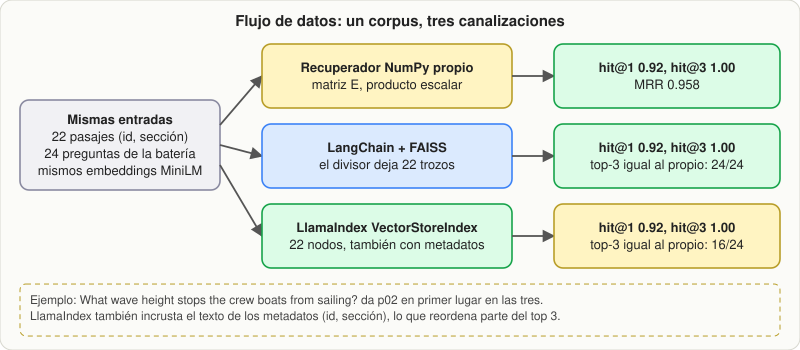

In [8]:
diagram(800, 350, [
    ("box", 20, 100, 200, 90, "Mismas entradas\n22 pasajes (id, sección)\n24 preguntas de la batería\nmismos embeddings MiniLM", "grey"),
    ("arrow", 220, 125, 262, 76, ""),
    ("arrow", 220, 145, 262, 156, ""),
    ("arrow", 220, 165, 262, 236, ""),
    ("box", 262, 44, 250, 64, "Recuperador NumPy propio\nmatriz E, producto escalar", "gold"),
    ("box", 262, 124, 250, 64, "LangChain + FAISS\nel divisor deja 22 trozos", "blue"),
    ("box", 262, 204, 250, 64, "LlamaIndex VectorStoreIndex\n22 nodos, también con metadatos", "green"),
    ("arrow", 512, 76, 554, 76, ""),
    ("arrow", 512, 156, 554, 156, ""),
    ("arrow", 512, 236, 554, 236, ""),
    ("box", 554, 44, 226, 64, "hit@1 0.92, hit@3 1.00\nMRR 0.958", "green"),
    ("box", 554, 124, 226, 64, "hit@1 0.92, hit@3 1.00\ntop-3 igual al propio: 24/24", "green"),
    ("box", 554, 204, 226, 64, "hit@1 0.92, hit@3 1.00\ntop-3 igual al propio: 16/24", "gold"),
    ("note", 20, 284, 760, 52, "Ejemplo: What wave height stops the crew boats from sailing? da p02 en primer lugar en las tres.\nLlamaIndex también incrusta el texto de los metadatos (id, sección), lo que reordena parte del top 3."),
], "Flujo de datos: un corpus, tres canalizaciones")

In [9]:
def row(name, search):
    m = evaluate(search)
    print(f"{name:34s} hit@1 {m['hit1']:.2f}   hit@3 {m['hit3']:.2f}   MRR {m['mrr']:.3f}")
    return m

m_own = row("own NumPy retriever", own)
m_lc = row("LangChain + FAISS", lc_search)
m_li = row("LlamaIndex VectorStoreIndex", li_search)
qs = [q for _, q, _ in BATTERY]
agree = lambda a, b, k: sum(a(q)[:k] == b(q)[:k] for q in qs)
print(f"\nsame top-1 on {agree(own, lc_search, 1)}/{len(qs)} questions (own vs LangChain) and {agree(own, li_search, 1)}/{len(qs)} (own vs LlamaIndex)")
print(f"same ordered top-3: own vs LangChain {agree(own, lc_search, 3)}/{len(qs)}, own vs LlamaIndex {agree(own, li_search, 3)}/{len(qs)}")
from llama_index.core.schema import MetadataMode
node = next(iter(li_index.docstore.docs.values()))
print("\ntext LlamaIndex embeds for one node by default:\n  ", repr(node.get_content(metadata_mode=MetadataMode.EMBED)[:110]))

own NumPy retriever                hit@1 0.92   hit@3 1.00   MRR 0.958


LangChain + FAISS                  hit@1 0.92   hit@3 1.00   MRR 0.958


LlamaIndex VectorStoreIndex        hit@1 0.92   hit@3 1.00   MRR 0.958



same top-1 on 24/24 questions (own vs LangChain) and 24/24 (own vs LlamaIndex)


same ordered top-3: own vs LangChain 24/24, own vs LlamaIndex 16/24

text LlamaIndex embeds for one node by default:
   'id: p01\nsection: Safety / Access\n\nSafety / Access. Technicians must hold a valid GWO Basic Safety Training cer'


In [10]:
loc = {name: len([l for l in inspect.getsource(fn).splitlines() if l.strip() and not l.strip().startswith("#")])
       for name, fn in [("own NumPy retriever", build_own), ("LangChain + FAISS", build_langchain), ("LlamaIndex", build_llamaindex)]}
def class_source(name):
    # las clases definidas en un notebook no tienen archivo fuente: se leen del historial de celdas
    cell = next(c for c in get_ipython().user_ns["_ih"] if f"class {name}(" in c)
    start = cell.index(f"class {name}(")
    block = cell[start:].split("\n")
    out = [block[0]]
    for line in block[1:]:
        if line.strip() and not line.startswith(" "):
            break
        out.append(line)
    return "\n".join(out)

extra = {"LangChain + FAISS": class_source("MiniLMEmbeddings"), "LlamaIndex": class_source("MiniLMLlama")}
print("non-blank, non-comment lines of the build function (+ the embedding adapter each framework needs):")
for name, n in loc.items():
    adapter = len([l for l in extra.get(name, "").splitlines() if l.strip()])
    print(f"  {name:22s}{n:4d}  + adapter {adapter:3d}")

def fresh_import_seconds(stmt):
    code_ = f"import time; t = time.perf_counter(); {stmt}; print(time.perf_counter() - t)"
    out = [float(subprocess.run([sys.executable, "-c", code_], capture_output=True, text=True).stdout.strip().splitlines()[-1]) for _ in range(2)]
    return min(out)

import importlib.metadata as md_
def installed_mb(*dists):
    total, seen = 0, set()
    for d in dists:
        try:
            for f in md_.files(d) or []:
                p = f.locate()
                if str(p) not in seen and p.exists():
                    seen.add(str(p)); total += p.stat().st_size
        except md_.PackageNotFoundError:
            pass
    return total / 1e6

print("\nimport time in a fresh interpreter (best of 2) and size of the framework's own packages:")
for label, stmt, dists in [
    ("numpy only", "import numpy", ["numpy"]),
    ("LangChain + FAISS", "from langchain_core.documents import Document; from langchain_community.vectorstores import FAISS; from langchain_text_splitters import RecursiveCharacterTextSplitter", ["langchain-core", "langchain-community", "langchain-text-splitters", "faiss-cpu"]),
    ("LlamaIndex", "from llama_index.core import VectorStoreIndex", ["llama-index-core"]),
]:
    print(f"  {label:20s}{fresh_import_seconds(stmt):6.2f} s import   {installed_mb(*dists):6.0f} MB installed")

non-blank, non-comment lines of the build function (+ the embedding adapter each framework needs):
  own NumPy retriever      6  + adapter   0
  LangChain + FAISS        6  + adapter   5
  LlamaIndex               6  + adapter   5

import time in a fresh interpreter (best of 2) and size of the framework's own packages:


  numpy only            0.16 s import       65 MB installed


  LangChain + FAISS     1.48 s import       94 MB installed


  LlamaIndex            2.56 s import       27 MB installed


Lee los tres resultados juntos:

* **La calidad de la recuperación es una propiedad del modelo de embeddings y del troceado, no del framework.** Los
  tres recuperadores obtienen exactamente el mismo hit@1, hit@3 y MRR. Nuestro recuperador NumPy y LangChain+FAISS
  devuelven el mismo top tres ordenado en todas las preguntas. LlamaIndex coincide en el primer resultado en todas,
  pero ordena de otro modo el 2.º y el 3.º en algunas preguntas, y la última línea impresa muestra por qué: **por
  defecto calcula el embedding de los metadatos del nodo (`id`, `section`) junto con el texto**, así que el vector que
  busca no es el vector que tú construiste. Es un valor por defecto del framework que cambia en silencio tu
  recuperación, y solo lo notas porque comparaste con una referencia. (El ejercicio 3 alinea los dos.) Elegir un
  framework u otro no hará que las respuestas sean mejores ni peores; el módulo 07 muestra qué sí lo hace.
* **A esta escala los frameworks cuestan peso y un adaptador, no líneas.** Las funciones de construcción tienen la
  misma longitud (unas seis líneas cada una) y cada framework necesita además un adaptador de cinco líneas para
  usar nuestro modelo local, que es donde normalmente se conectaría un modelo alojado. El precio real es el tiempo de
  importación y el tamaño instalado, medidos arriba: muy por encima de los de NumPy. En un servidor siempre activo y
  con poca memoria eso importa (un punto al que vuelve el módulo de producción).
* **Lo que compras es intercambiabilidad y ecosistema**: cien almacenes vectoriales, cargadores de PDF y bases de
  datos, callbacks de trazado (módulo 09), agentes y grafos (módulo 05). Si los necesitas, el coste compensa; si
  necesitas un solo recuperador sobre un solo corpus, no.

## 6. Qué abstrae cada framework y cuándo prescindir de ambos

| Aspecto | Nuestro código | LangChain | LlamaIndex |
|---|---|---|---|
| Unidad de texto | una cadena y un id | `Document` con `metadata` | `Document`, dividido en `Node`s que conservan su origen |
| Embedding | llamar al modelo | interfaz `Embeddings` | interfaz `BaseEmbedding` |
| Índice | una matriz NumPy | cualquier `VectorStore` (FAISS, pgvector, ...) | `VectorStoreIndex` sobre un almacén intercambiable |
| Recuperación | `argsort` | `retriever.invoke` | `index.as_retriever`, con nodos puntuados |
| Composición | funciones simples | cadenas unidas con el operador pipe (LCEL), después LangGraph | motores de consulta, enrutadores, agentes |
| Síntesis de la respuesta | tu propio prompt | una cadena que ensamblas | integrada en el motor de consultas |
| Más fuerte en | claridad, huella mínima | integraciones amplias, componer pasos | indexar datos estructurados y mixtos, patrones de consulta incluidos |

**Cuándo prescindir de ambos.** Un corpus, un recuperador, unos pocos miles de trozos, un servicio que debe seguir
siendo pequeño: la docena de líneas de NumPy de la sección 2 es más fácil de leer, probar y mantener correcta, y se
importa al instante. El componente de recuperación de un pequeño endpoint de búsqueda de este portafolio es BM25 puro
exactamente por eso. Recurre a un framework cuando necesites lo que aporta (almacenes intercambiables, muchos
cargadores, ganchos de trazado, grafos de pasos), no por defecto; y no mezcles dos frameworks sin un motivo. El agente
de parques eólicos mantuvo dos pilas porque los dos corpus tenían formas distintas (narrativas de incidencias en texto
libre frente a especificaciones estructuradas) y cada framework encajaba mejor con uno, y porque el agente solo ve
ambos a través de una única función `search`, de modo que la elección queda local.

## Ejercicios

1. Cambia el divisor a `chunk_size=80` y reconstruye el almacén de LangChain. ¿Cuántos trozos obtienes y qué ocurre
   con el hit@1 y con la legibilidad de un trozo citado?
2. Añade un recuperador con `k=2` a la cadena LCEL e imprime qué pasajes ve el generador sustituto en las preguntas
   parafraseadas. ¿Dónde falla, y la culpa es de la recuperación o del generador?
3. Haz que LlamaIndex calcule el embedding solo del texto: fija `excluded_embed_metadata_keys=["id", "section"]` en
   cada `Document` y reconstruye. ¿Coincide ahora su top tres ordenado con el de los otros dos en todas las preguntas?
4. Escribe un cuarto recuperador: el BM25 del módulo 01 detrás de la misma función `search(question)`, y evalúalo con
   el mismo `evaluate`. ¿Cuál de los cuatro llevarías a producción para este corpus, y por qué?